# Projet 04 — Prévision de la consommation électrique et des émissions (Tétouan)
**Étape 3 : prototype** · Module Management de projet et transition bas-carbone · ENSA Fès

**Question du projet.** Un modèle d'apprentissage automatique prévoit-il la consommation d'électricité de Tétouan plus précisément qu'une référence simple, de façon stable dans le temps et assez lisible pour un gestionnaire ?

**Cadre de prévision retenu (à justifier en soutenance).** Prévision *la veille pour le lendemain* à pas horaire. Pour l'heure `t`, on dispose de la charge jusqu'à `t − 24 h` seulement (retards d'au moins 24 h), du calendrier, et de la météo de l'heure `t`.

**Statut des données.**
| Élément | Nature |
|---|---|
| Consommations des trois zones, météo locale (2017) | Observées (SCADA Amendis, UCI n° 849, CC BY 4.0) |
| Calendrier, jours fériés, Ramadan | Construites par le groupe (dates islamiques à confirmer) |
| Émissions | **Estimées** : énergie × facteur d'émission (3 scénarios), jamais mesurées |
| Données simulées | Aucune |

**Hypothèse optimiste à signaler.** La météo de l'heure `t` utilisée en entrée est la météo *observée*, comme si la prévision météo était parfaite. En exploitation réelle, l'erreur de prévision météo s'ajouterait à celle du modèle.

## 1. Configuration et chargement des données

In [1]:
from pathlib import Path
import time, json, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from forecast_utils import ResidualModel

warnings.filterwarnings("ignore")
SEED = 42
DATA_DIR, ART = Path("data"), Path("artifacts")
DATA_DIR.mkdir(exist_ok=True); ART.mkdir(exist_ok=True)
CSV_LOCAL = DATA_DIR / "Tetuan City power consumption.csv" if (DATA_DIR / "Tetuan City power consumption.csv").exists() else DATA_DIR / "Tetuan_City_power_consumption.csv"
UCI_OLD_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00616/Tetuan%20City%20power%20consumption.csv"

ZONES = ["Zone 1 Power Consumption", "Zone 2 Power Consumption", "Zone 3 Power Consumption"]

def load_raw():
    """Charge le jeu UCI n° 849. Ordre : fichier local, ucimlrepo, ancienne URL UCI."""
    if CSV_LOCAL.exists():
        df = pd.read_csv(CSV_LOCAL)
    else:
        df = None
        try:
            from ucimlrepo import fetch_ucirepo
            d = fetch_ucirepo(id=849)
            df = pd.concat([d.data.features, d.data.targets], axis=1)
        except Exception as e:
            print("ucimlrepo indisponible :", type(e).__name__)
        if df is None:
            try:
                df = pd.read_csv(UCI_OLD_URL)
            except Exception as e:
                raise SystemExit(
                    "Téléchargement impossible. Téléchargez le fichier depuis "
                    "https://archive.ics.uci.edu/dataset/849 et placez-le dans "
                    f"{CSV_LOCAL}") from e
        df.to_csv(CSV_LOCAL, index=False)
    df.columns = [" ".join(c.split()) for c in df.columns]   # espaces doublés dans les en-têtes
    try:
        df["DateTime"] = pd.to_datetime(df["DateTime"], format="%m/%d/%Y %H:%M")
    except ValueError:
        df["DateTime"] = pd.to_datetime(df["DateTime"])
    return df

raw = load_raw()
print(raw.shape)
raw.head()

(52416, 9)


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


## 2. Fiche de qualité des données
Contrôles : doublons d'horodatage, trous, valeurs manquantes, plages, séquences figées. **Unités :** la fiche UCI ne les précise pas ; on suppose des kW (à confirmer dans l'article de Salam et El Hibaoui, 2018). Une énergie en kWh sur une heure vaut alors la puissance moyenne horaire × 1 h.

In [2]:
q = {}
q["lignes"] = len(raw)
q["debut"], q["fin"] = str(raw.DateTime.min()), str(raw.DateTime.max())
q["horodatages_dupliques"] = int(raw.DateTime.duplicated().sum())
q["valeurs_manquantes"] = int(raw.isna().sum().sum())
steps = raw.DateTime.sort_values().diff().value_counts()
q["pas_de_temps_observes"] = {str(k): int(v) for k, v in steps.items()}
full = pd.date_range(raw.DateTime.min(), raw.DateTime.max(), freq="10min")
q["pas_manquants"] = int(len(full.difference(raw.DateTime)))
for z in ZONES:   # séquences figées de 6 pas (1 h) ou plus
    flat = (raw[z].diff() == 0).astype(int).groupby((raw[z].diff() != 0).cumsum()).sum()
    q[f"sequences_figees_>=6 ({z[:6]})"] = int((flat >= 6).sum())
print(json.dumps(q, indent=2, ensure_ascii=False))
raw.describe().T[["min", "mean", "max"]].round(2)

{
  "lignes": 52416,
  "debut": "2017-01-01 00:00:00",
  "fin": "2017-12-30 23:50:00",
  "horodatages_dupliques": 0,
  "valeurs_manquantes": 0,
  "pas_de_temps_observes": {
    "0 days 00:10:00": 52415
  },
  "pas_manquants": 0,
  "sequences_figees_>=6 (Zone 1)": 0,
  "sequences_figees_>=6 (Zone 2)": 0,
  "sequences_figees_>=6 (Zone 3)": 0
}


,min,mean,max
DateTime,2017-01-01 00:00:00,2017-07-01 23:55:00,2017-12-30 23:50:00
Temperature,3.247,18.810024,40.01
Humidity,11.34,68.259518,94.8
Wind Speed,0.05,1.959489,6.483
general diffuse flows,0.004,182.696614,1163.0
diffuse flows,0.011,75.028022,936.0
Zone 1 Power Consumption,13895.6962,32344.970564,52204.39512
Zone 2 Power Consumption,8560.081466,21042.509082,37408.86076
Zone 3 Power Consumption,5935.17407,17835.406218,47598.32636


## 3. Construction du jeu horaire et des variables
Toutes les variables dérivées de la charge utilisent un décalage d'au moins 24 h : aucune information postérieure à `t − 24 h` n'entre dans la prédiction de `t` (exigences E1 et E2).

**Jours fériés et Ramadan 2017.** Les fêtes civiles fixes sont sûres. Les dates des fêtes religieuses et du Ramadan dépendent de l'observation de la lune : **à confirmer** dans le calendrier officiel avant le rendu.

In [3]:
HOLIDAYS = pd.to_datetime([
    "2017-01-01", "2017-01-11", "2017-05-01", "2017-07-30", "2017-08-14",
    "2017-08-20", "2017-08-21", "2017-11-06", "2017-11-18",                 # fêtes civiles fixes
    "2017-06-25", "2017-06-26", "2017-09-01", "2017-09-02",                 # Aïd al-Fitr, Aïd al-Adha (à confirmer)
    "2017-09-21", "2017-12-01",                                             # nouvel an hégirien, Mawlid (à confirmer)
])
RAMADAN = (pd.Timestamp("2017-05-27"), pd.Timestamp("2017-06-24"))          # à confirmer

hourly = raw.set_index("DateTime").sort_index().resample("h").mean()
hourly["load_kw"] = hourly[ZONES].sum(axis=1)
print("heures manquantes après agrégation :", int(hourly["load_kw"].isna().sum()))

def build_features(h):
    f = pd.DataFrame(index=h.index)
    d = h.index.normalize()
    f["hour"], f["dow"] = h.index.hour, h.index.dayofweek
    f["is_weekend"] = (f["dow"] >= 5).astype(int)
    f["is_holiday"] = d.isin(HOLIDAYS).astype(int)
    f["is_ramadan"] = ((d >= RAMADAN[0]) & (d <= RAMADAN[1])).astype(int)
    f["temp"], f["humidity"], f["wind"] = h["Temperature"], h["Humidity"], h["Wind Speed"]
    f["diffuse_general"], f["diffuse"] = h["general diffuse flows"], h["diffuse flows"]
    f["hdd"], f["cdd"] = np.maximum(18 - f["temp"], 0), np.maximum(f["temp"] - 18, 0)
    y = h["load_kw"]
    f["lag_24"], f["lag_48"], f["lag_168"] = y.shift(24), y.shift(48), y.shift(168)
    f["roll_24"] = y.shift(24).rolling(24).mean()
    f["roll_168"] = y.shift(24).rolling(168).mean()
    return f

X_all = build_features(hourly)
data = X_all.assign(load_kw=hourly["load_kw"]).dropna()
FEATURES = [c for c in data.columns if c != "load_kw"]
print(len(data), "lignes utilisables, du", data.index.min(), "au", data.index.max())
print("Variables :", FEATURES)

heures manquantes après agrégation : 0
8545 lignes utilisables, du 2017-01-08 23:00:00 au 2017-12-30 23:00:00
Variables : ['hour', 'dow', 'is_weekend', 'is_holiday', 'is_ramadan', 'temp', 'humidity', 'wind', 'diffuse_general', 'diffuse', 'hdd', 'cdd', 'lag_24', 'lag_48', 'lag_168', 'roll_24', 'roll_168']


## 3 bis. Test anti-fuite d'information (risque R1, exigence E2)
On perturbe la charge à partir d'un instant `t0`, puis on reconstruit les variables : toute variable située **avant `t0 + 24 h`** doit rester strictement identique. Sinon, une variable utilise une information trop récente.

In [4]:
t0 = pd.Timestamp("2017-09-15 00:00")
h2 = hourly.copy(); h2.loc[t0:, "load_kw"] = h2.loc[t0:, "load_kw"] * 2 + 5000
f_a, f_b = build_features(hourly), build_features(h2)
cols_load = ["lag_24", "lag_48", "lag_168", "roll_24", "roll_168"]
safe = f_a.index < t0 + pd.Timedelta(hours=24)
ok = np.allclose(f_a.loc[safe, cols_load].dropna().values, f_b.loc[safe, cols_load].dropna().values)
print("Aucune variable de charge ne voit les 24 dernières heures :", ok)
assert ok

Aucune variable de charge ne voit les 24 dernières heures : True


## 4. Découpage chronologique (exigence E1)
| Période | Usage |
|---|---|
| 9 janvier – 31 août | Entraînement |
| Septembre – octobre | Validation (choix des hyperparamètres et de la référence) |
| Novembre – 30 décembre | Essai (utilisé une seule fois pour l'évaluation finale) |

**Limite à garder en tête.** Une seule année de données : l'essai (novembre–décembre) contient des conditions hivernales vues seulement en janvier–février à l'entraînement. Aucun modèle n'a vu un deuxième cycle annuel complet.

entraînement   5641 h  2017-01-08 → 2017-08-31
validation     1464 h  2017-09-01 → 2017-10-31
essai          1440 h  2017-11-01 → 2017-12-30


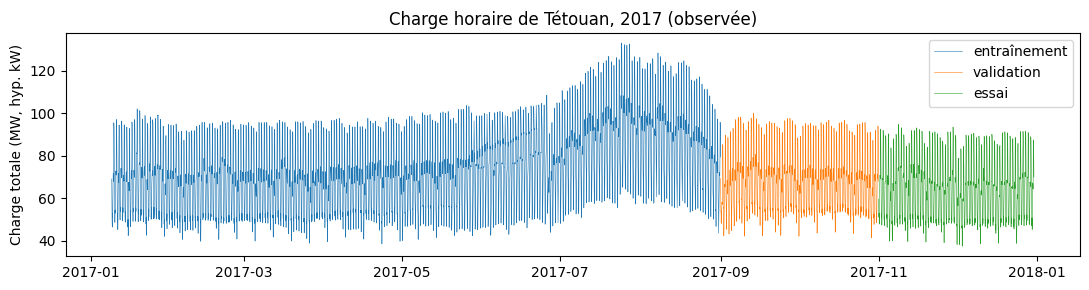

In [5]:
tr = data.loc[:"2017-08-31 23:00"]
va = data.loc["2017-09-01":"2017-10-31 23:00"]
te = data.loc["2017-11-01":]
trva = data.loc[:"2017-10-31 23:00"]
for name, s in [("entraînement", tr), ("validation", va), ("essai", te)]:
    print(f"{name:13s} {len(s):5d} h  {s.index.min().date()} → {s.index.max().date()}")

fig, ax = plt.subplots(figsize=(11, 3))
for s, c, l in [(tr, "tab:blue", "entraînement"), (va, "tab:orange", "validation"), (te, "tab:green", "essai")]:
    ax.plot(s.index, s["load_kw"] / 1000, lw=0.4, color=c, label=l)
ax.set_ylabel("Charge totale (MW, hyp. kW)"); ax.legend(); ax.set_title("Charge horaire de Tétouan, 2017 (observée)")
plt.tight_layout(); plt.show()

## 5. Références (méthodes statistiques simples)
Trois références sont comparées sur la validation ; la meilleure devient *la* référence du projet.
- **Naïve 24 h** : même heure la veille.
- **Naïve 168 h** : même heure la semaine précédente.
- **Profil moyen** : moyenne de l'entraînement pour chaque couple (jour de semaine, heure).

In [6]:
def metrics(y, p):
    e = np.asarray(p) - np.asarray(y)
    return {"MAE": float(np.mean(np.abs(e))), "RMSE": float(np.sqrt(np.mean(e**2))),
            "MAPE_%": float(np.mean(np.abs(e) / np.asarray(y)) * 100), "biais": float(np.mean(e))}

def profile_pred(train, target):
    prof = train.groupby(["dow", "hour"])["load_kw"].mean()
    idx = pd.MultiIndex.from_arrays([target["dow"], target["hour"]])
    return prof.reindex(idx).values

def baseline_preds(train, target):
    return {"Naïve 24 h": target["lag_24"].values,
            "Naïve 168 h": target["lag_168"].values,
            "Profil moyen": profile_pred(train, target)}

val_base = {k: metrics(va["load_kw"], v) for k, v in baseline_preds(tr, va).items()}
val_base_df = pd.DataFrame(val_base).T.round(1)
BASELINE = val_base_df["RMSE"].idxmin()
print("Référence retenue (RMSE de validation le plus bas) :", BASELINE)
val_base_df

Référence retenue (RMSE de validation le plus bas) : Naïve 24 h


,MAE,RMSE,MAPE_%,biais
Naïve 24 h,2310.1,3359.7,3.6,27.5
Naïve 168 h,3071.4,5266.3,4.6,1146.3
Profil moyen,6531.9,7880.8,9.6,5860.2


## 6. Modèles et réglage sur la validation
Régression linéaire (heure et jour de semaine en variables indicatrices), forêt aléatoire, XGBoost. Les grilles sont volontairement **limitées** (réglage plafonné, risque R5). Le temps de réglage est mesuré, car il fait partie du coût de complexité.

In [7]:
def make_linear():
    pre = ColumnTransformer([
        ("oh", OneHotEncoder(handle_unknown="ignore"), ["hour", "dow"]),
        ("num", StandardScaler(), [c for c in FEATURES if c not in ("hour", "dow")])])
    return Pipeline([("pre", pre), ("lr", LinearRegression())])

def make_rf(**p):  return RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **p)
def make_xgb(**p): return XGBRegressor(random_state=SEED, n_jobs=-1, tree_method="hist",
                                       subsample=0.8, colsample_bytree=0.8, **p)

def grid(d): return [dict(zip(d, v)) for v in itertools.product(*d.values())]
RF_GRID  = grid({"max_depth": [12, None], "min_samples_leaf": [1, 5], "max_features": [0.5, 1.0]})
XGB_GRID = grid({"max_depth": [3, 5, 7], "learning_rate": [0.03, 0.1], "n_estimators": [150, 300, 600]})

def tune(make, params_list):
    rows, t0 = [], time.perf_counter()
    for p in params_list:
        m = make(**p).fit(tr[FEATURES], tr["load_kw"])
        rows.append({**p, "RMSE_val": metrics(va["load_kw"], m.predict(va[FEATURES]))["RMSE"]})
    res = pd.DataFrame(rows).sort_values("RMSE_val")
    return res, time.perf_counter() - t0

rf_res, rf_tune_s = tune(make_rf, RF_GRID)
xgb_res, xgb_tune_s = tune(make_xgb, XGB_GRID)
best_rf  = {k: (None if pd.isna(v) else (int(v) if k != "max_features" else float(v)))
            for k, v in rf_res.iloc[0].drop("RMSE_val").items()}
best_xgb = {k: (int(v) if k != "learning_rate" else float(v))
            for k, v in xgb_res.iloc[0].drop("RMSE_val").items()}
print(f"Réglage RF : {rf_tune_s:.0f} s, {len(RF_GRID)} combinaisons → {best_rf}")
print(f"Réglage XGBoost : {xgb_tune_s:.0f} s, {len(XGB_GRID)} combinaisons → {best_xgb}")
xgb_res.head(5).round(3)

Réglage RF : 13 s, 8 combinaisons → {'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0}
Réglage XGBoost : 7 s, 18 combinaisons → {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 300}


,max_depth,learning_rate,n_estimators,RMSE_val
7,5,0.03,300,2250.707
6,5,0.03,150,2273.995
8,5,0.03,600,2286.912
12,7,0.03,150,2328.548
2,3,0.03,600,2329.741


## 7. Évaluation finale sur la période d'essai
Après le réglage, chaque modèle est réentraîné sur entraînement + validation, puis évalué **une fois** sur novembre–décembre. Le modèle retenu pour l'API est choisi sur la **validation**, pas sur l'essai, pour ne pas sélectionner sur le jeu de test.

In [8]:
MAKERS = {"Régression linéaire": make_linear,
          "Forêt aléatoire": lambda: make_rf(**best_rf),
          "XGBoost": lambda: make_xgb(**best_xgb),
          "XGBoost sur écart à la veille": lambda: ResidualModel(make_xgb(**best_xgb), base_col="lag_24")}

def fit_eval(make):
    t0 = time.perf_counter(); m = make().fit(trva[FEATURES], trva["load_kw"]); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); p = m.predict(te[FEATURES]); pred_s = time.perf_counter() - t0
    return m, p, fit_s, pred_s

preds, fitted, rows = {}, {}, []
base_p = baseline_preds(trva, te)[BASELINE]
preds[f"Référence ({BASELINE})"] = base_p
rows.append({"Modèle": f"Référence ({BASELINE})", **metrics(te["load_kw"], base_p), "entraînement_s": 0.0, "prédiction_s": 0.0})
for name, mk in MAKERS.items():
    m, p, fs, ps = fit_eval(mk); fitted[name], preds[name] = m, p
    rows.append({"Modèle": name, **metrics(te["load_kw"], p), "entraînement_s": fs, "prédiction_s": ps})

test_df = pd.DataFrame(rows).set_index("Modèle")
ref_rmse, ref_mae = test_df.iloc[0]["RMSE"], test_df.iloc[0]["MAE"]
test_df["gain_RMSE_%"] = (1 - test_df["RMSE"] / ref_rmse) * 100
test_df["gain_MAE_%"] = (1 - test_df["MAE"] / ref_mae) * 100
test_df.round(2)

,MAE,RMSE,MAPE_%,biais,entraînement_s,prédiction_s,gain_RMSE_%,gain_MAE_%
Modèle,,,,,,,,
Référence (Naïve 24 h),2076.12,3188.24,3.33,55.09,0.00,0.00,0.00,0.00
Régression linéaire,1558.34,2099.86,2.54,40.18,0.03,0.01,34.14,24.94
Forêt aléatoire,1621.74,2342.03,2.56,356.96,3.31,0.10,26.54,21.89
XGBoost,1502.61,2091.03,2.39,450.00,0.41,0.01,34.41,27.62
XGBoost sur écart à la veille,1471.24,2037.39,2.33,674.85,0.35,0.01,36.10,29.14


RMSE de validation : {'Régression linéaire': 2453.4, 'Forêt aléatoire': 2362.1, 'XGBoost': 2250.7, 'XGBoost sur écart à la veille': 2247.2}
Modèle retenu sur la validation : XGBoost sur écart à la veille


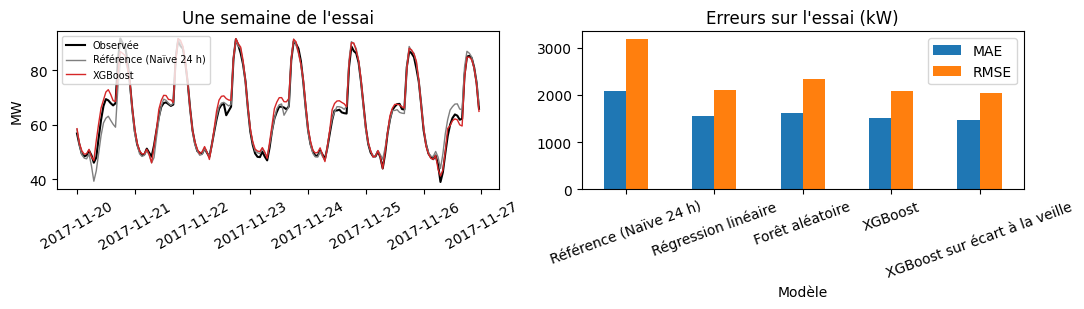

In [9]:
# Choix du modèle ML sur la validation (jamais sur l'essai)
val_scores = {}
for name, mk in MAKERS.items():
    m = mk().fit(tr[FEATURES], tr["load_kw"])
    val_scores[name] = metrics(va["load_kw"], m.predict(va[FEATURES]))["RMSE"]
SELECTED = min(val_scores, key=val_scores.get)
print("RMSE de validation :", {k: round(v, 1) for k, v in val_scores.items()})
print("Modèle retenu sur la validation :", SELECTED)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
wk = te.loc["2017-11-20":"2017-11-26"]
axes[0].plot(wk.index, wk["load_kw"] / 1000, color="k", lw=1.5, label="Observée")
for name, c in [(f"Référence ({BASELINE})", "tab:gray"), ("XGBoost", "tab:red")]:
    s = pd.Series(preds[name], index=te.index).loc[wk.index]
    axes[0].plot(s.index, s / 1000, lw=1, color=c, label=name)
axes[0].set_title("Une semaine de l'essai"); axes[0].set_ylabel("MW"); axes[0].legend(fontsize=7)
axes[0].tick_params(axis="x", labelrotation=30)
test_df[["MAE", "RMSE"]].plot.bar(ax=axes[1]); axes[1].set_title("Erreurs sur l'essai (kW)")
axes[1].tick_params(axis="x", labelrotation=20)
plt.tight_layout(); plt.show()

## 8. Stabilité dans le temps : validation glissante mensuelle (objectif O4)
Pour chaque mois de juillet à décembre, on entraîne sur tout ce qui précède et on teste sur le mois. Les hyperparamètres sont ceux du réglage ci-dessus. **Attention :** ils ont été choisis avec septembre–octobre, donc ces deux mois sont légèrement favorisés. Juillet est évalué par des modèles qui n'ont jamais vu l'été.

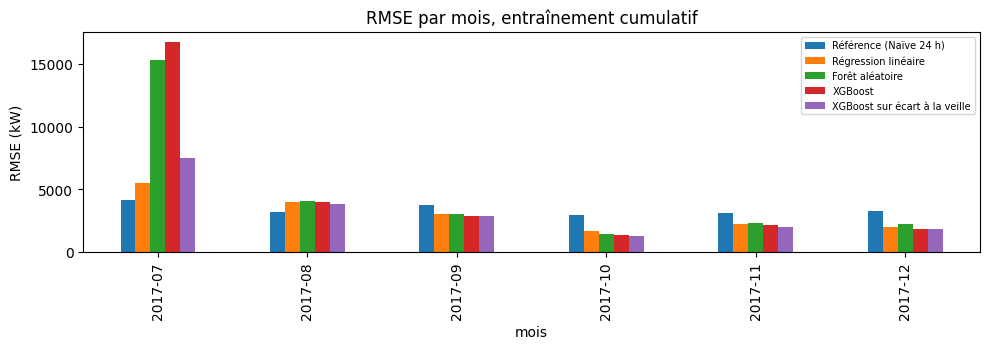

Biais moyen par mois (kW, négatif = sous-estimation) :


,Référence (Naïve 24 h),Régression linéaire,Forêt aléatoire,XGBoost,XGBoost sur écart à la veille
mois,,,,,
2017-07,-579.0,-4722.0,-11556.0,-13683.0,-5178.0
2017-08,801.0,2759.0,2736.0,2751.0,390.0
2017-09,102.0,492.0,499.0,549.0,440.0
2017-10,-45.0,309.0,97.0,199.0,144.0
2017-11,59.0,70.0,353.0,392.0,423.0
2017-12,51.0,3.0,413.0,310.0,386.0


,RMSE moyen,écart-type,pire mois
Référence (Naïve 24 h),3389.0,436.0,4106.0
Régression linéaire,3072.0,1456.0,5501.0
Forêt aléatoire,4719.0,5272.0,15326.0
XGBoost,4810.0,5902.0,16713.0
XGBoost sur écart à la veille,3216.0,2267.0,7481.0


In [10]:
FOLDS = [("2017-07-01", "2017-07-31 23:00"), ("2017-08-01", "2017-08-31 23:00"), ("2017-09-01", "2017-09-30 23:00"),
         ("2017-10-01", "2017-10-31 23:00"), ("2017-11-01", "2017-11-30 23:00"), ("2017-12-01", "2017-12-30 23:00")]
bt_rmse, bt_bias = [], []
for a, b in FOLDS:
    train_f, test_f = data.loc[:pd.Timestamp(a) - pd.Timedelta(hours=1)], data.loc[a:b]
    r, bi = {"mois": a[:7]}, {"mois": a[:7]}
    mb = metrics(test_f["load_kw"], baseline_preds(train_f, test_f)[BASELINE])
    r[f"Référence ({BASELINE})"], bi[f"Référence ({BASELINE})"] = mb["RMSE"], mb["biais"]
    for name, mk in MAKERS.items():
        m = mk().fit(train_f[FEATURES], train_f["load_kw"])
        mm = metrics(test_f["load_kw"], m.predict(test_f[FEATURES]))
        r[name], bi[name] = mm["RMSE"], mm["biais"]
    bt_rmse.append(r); bt_bias.append(bi)
bt = pd.DataFrame(bt_rmse).set_index("mois")
bt_bias = pd.DataFrame(bt_bias).set_index("mois")
ax = bt.plot.bar(figsize=(10, 3.6)); ax.set_ylabel("RMSE (kW)"); ax.set_title("RMSE par mois, entraînement cumulatif")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print("Biais moyen par mois (kW, négatif = sous-estimation) :")
display(bt_bias.round(0))
bt_summary = pd.DataFrame({"RMSE moyen": bt.mean(), "écart-type": bt.std(), "pire mois": bt.max()}).round(0)
bt_summary

## 9. Coût de calcul et interprétabilité (objectif O5)
Importance par permutation sur l'essai (hausse du RMSE quand on mélange une variable) pour XGBoost, et coefficients standardisés pour la régression.

,entraînement_s,prédiction_s,réglage_s
Modèle,,,
Référence (Naïve 24 h),0.00,0.00,0.00
Régression linéaire,0.03,0.01,0.00
Forêt aléatoire,3.31,0.10,13.12
XGBoost,0.41,0.01,7.39
XGBoost sur écart à la veille,0.35,0.01,0.00


Importance par permutation (hausse du RMSE, kW) :
lag_24             10988.0
lag_48              1898.0
lag_168             1373.0
dow                  698.0
hour                 340.0
is_holiday           139.0
diffuse_general       59.0
diffuse               27.0


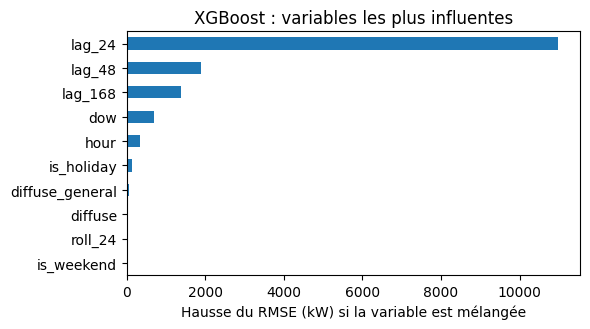

In [11]:
cost = test_df[["entraînement_s", "prédiction_s"]].copy()
cost["réglage_s"] = pd.Series({"Forêt aléatoire": rf_tune_s, "XGBoost": xgb_tune_s}).reindex(cost.index).fillna(0)
display(cost.round(2))

pi = permutation_importance(fitted["XGBoost"], te[FEATURES], te["load_kw"], n_repeats=5, random_state=SEED,
                            scoring="neg_root_mean_squared_error", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print("Importance par permutation (hausse du RMSE, kW) :"); print(imp.head(8).round(0).to_string())
fig, ax = plt.subplots(figsize=(6, 3.4)); imp.head(10)[::-1].plot.barh(ax=ax)
ax.set_xlabel("Hausse du RMSE (kW) si la variable est mélangée"); ax.set_title("XGBoost : variables les plus influentes")
plt.tight_layout(); plt.show()

## 9 bis. Les écarts entre modèles sont-ils significatifs ?
L'essai ne contient que 60 jours : un écart de quelques pourcents peut être du bruit. On rééchantillonne les **jours** de l'essai avec remise (2 000 tirages, mêmes jours pour tous les modèles) et on calcule un intervalle à 95 % du rapport de RMSE. Un intervalle qui contient 1 signifie que l'écart n'est pas distinguable du hasard sur cet essai. Ce test ne couvre **pas** le changement de saison (voir la section 8).

In [12]:
rng = np.random.default_rng(SEED)
sq = pd.DataFrame({n: (np.asarray(p) - te["load_kw"].values) ** 2 for n, p in preds.items()}, index=te.index)
daily = sq.groupby(sq.index.normalize()).mean()                  # erreur quadratique moyenne par jour (24 h chacun)
B, nd = 2000, len(daily)
draws = rng.integers(0, nd, size=(B, nd))
rm = {n: np.sqrt(daily[n].values[draws].mean(axis=1)) for n in daily.columns}
ref_n = f"Référence ({BASELINE})"
rows = []
for n in daily.columns:
    if n == ref_n: continue
    r_ref, r_lin = rm[n] / rm[ref_n], rm[n] / rm["Régression linéaire"]
    rows.append({"Modèle": n,
                 "RMSE / référence": f"{np.median(r_ref):.2f} [{np.percentile(r_ref,2.5):.2f} ; {np.percentile(r_ref,97.5):.2f}]",
                 "RMSE / régression": "—" if n == "Régression linéaire" else f"{np.median(r_lin):.2f} [{np.percentile(r_lin,2.5):.2f} ; {np.percentile(r_lin,97.5):.2f}]"})
pd.DataFrame(rows).set_index("Modèle")

,RMSE / référence,RMSE / régression
Modèle,,
Régression linéaire,0.66 [0.60 ; 0.73],—
Forêt aléatoire,0.73 [0.62 ; 0.86],1.11 [0.98 ; 1.25]
XGBoost,0.66 [0.56 ; 0.77],0.99 [0.90 ; 1.10]
XGBoost sur écart à la veille,0.64 [0.53 ; 0.77],0.97 [0.84 ; 1.10]


## 10. Analyse des erreurs et des biais
Biais = prévision − observation (positif : surestimation). On examine le modèle retenu sur la validation, selon l'heure, le type de jour et la température.

Modèle analysé : XGBoost sur écart à la veille
Pointe (10 % des heures les plus chargées) : MAE 1501 kW, biais 376 kW


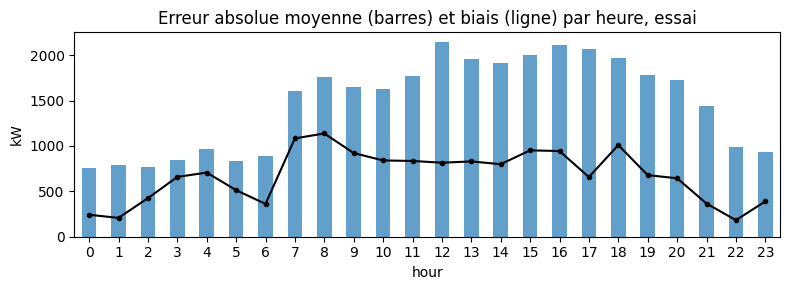

,heures,MAE,biais
type_jour,,,
férié,72,3355.0,2095.0
semaine,984,1279.0,506.0
week-end,384,1611.0,842.0


,heures,MAE,biais
tranche_temp,,,
"(-10, 10]",171,1062.0,711.0
"(10, 14]",383,1067.0,519.0
"(14, 18]",517,1556.0,1006.0
"(18, 40]",369,1962.0,355.0


In [13]:
best_pred = pd.Series(preds[SELECTED], index=te.index)
err = (best_pred - te["load_kw"]).rename("erreur")
tab = te.assign(erreur=err, abs_err=err.abs(), obs=te["load_kw"])
by_hour = tab.groupby("hour").agg(MAE=("abs_err", "mean"), biais=("erreur", "mean"))
tab["type_jour"] = np.where(tab["is_holiday"] == 1, "férié", np.where(tab["is_weekend"] == 1, "week-end", "semaine"))
by_day = tab.groupby("type_jour").agg(heures=("erreur", "size"), MAE=("abs_err", "mean"), biais=("erreur", "mean"))
tab["tranche_temp"] = pd.cut(tab["temp"], [-10, 10, 14, 18, 40])
by_temp = tab.groupby("tranche_temp", observed=True).agg(heures=("erreur", "size"), MAE=("abs_err", "mean"), biais=("erreur", "mean"))
peak = tab[tab["obs"] >= tab["obs"].quantile(0.9)]
print(f"Modèle analysé : {SELECTED}")
print(f"Pointe (10 % des heures les plus chargées) : MAE {peak['abs_err'].mean():.0f} kW, biais {peak['erreur'].mean():.0f} kW")
fig, ax = plt.subplots(figsize=(8, 3)); by_hour["MAE"].plot.bar(ax=ax, color="tab:blue", alpha=0.7)
by_hour["biais"].plot(ax=ax, color="k", marker="o", ms=3); ax.axhline(0, color="gray", lw=0.5)
ax.set_title("Erreur absolue moyenne (barres) et biais (ligne) par heure, essai"); ax.set_ylabel("kW")
plt.tight_layout(); plt.show()
display(by_day.round(0)); display(by_temp.round(0))

## 11. Estimation des émissions (valeurs calculées, non mesurées)
Émissions = énergie (kWh) × facteur d'émission du réseau. **Valeurs provisoires du groupe, à confirmer à la source primaire** (Ember, AIE) : borne haute ≈ 0,720 kgCO₂/kWh (Climate Analytics, année 2019), borne basse ≈ 0,596 kgCO₂/kWh (Ember, année 2025, relayé par un agrégateur), valeur centrale = milieu des deux. Aucun facteur propre à 2017 n'a été récupéré : appliquer ces facteurs aux données de 2017 est une approximation assumée.

Avec un facteur constant, l'erreur relative sur les émissions est identique à l'erreur relative sur l'énergie. L'apport du modèle se lit donc dans la consommation ; l'incertitude du facteur domine l'incertitude sur les émissions.

In [14]:
FACTORS = {"bas": 0.596, "central": 0.658, "haut": 0.720}      # kgCO2/kWh, provisoires
obs_kwh = te["load_kw"].sum()                                   # pas de 1 h : kW × 1 h = kWh
rows = []
for scen, ef in FACTORS.items():
    r = {"scénario": scen, "facteur kgCO2/kWh": ef, "observé (tCO2)": obs_kwh * ef / 1000}
    for name in [f"Référence ({BASELINE})", SELECTED]:
        r[f"{name} (tCO2)"] = preds[name].sum() * ef / 1000
        r[f"{name} écart %"] = (preds[name].sum() / obs_kwh - 1) * 100
    rows.append(r)
em = pd.DataFrame(rows).set_index("scénario")
print(f"Énergie observée sur l'essai : {obs_kwh/1e6:.1f} GWh (hypothèse : unités en kW)")
em.round(2)

Énergie observée sur l'essai : 92.8 GWh (hypothèse : unités en kW)


,facteur kgCO2/kWh,observé (tCO2),Référence (Naïve 24 h) (tCO2),Référence (Naïve 24 h) écart %,XGBoost sur écart à la veille (tCO2),XGBoost sur écart à la veille écart %
scénario,,,,,,
bas,0.60,55294.64,55341.92,0.09,55873.83,1.05
central,0.66,61046.77,61098.97,0.09,61686.20,1.05
haut,0.72,66798.90,66856.01,0.09,67498.58,1.05


## 12. Synthèse automatique et réponse à la question de soutenance
La cellule ci-dessous calcule les chiffres à citer. L'interprétation (« la complexité se justifie-t-elle ? ») reste un jugement du groupe, argumenté avec les tableaux ci-dessus.

In [15]:
ml = test_df.drop(index=test_df.index[0])
best_name = ml["RMSE"].idxmin()
lin = ml.loc["Régression linéaire"]
print(f"Référence retenue : {BASELINE}  (RMSE essai {ref_rmse:,.0f} kW, MAE {ref_mae:,.0f} kW)")
for n, r in ml.iterrows():
    print(f"  {n:32s} RMSE {r['RMSE']:7,.0f} kW  gain vs référence {r['gain_RMSE_%']:5.1f} %  | vs régression {(1 - r['RMSE']/lin['RMSE'])*100:+5.1f} %")
print(f"Meilleur modèle sur l'essai : {best_name}")
print(f"Modèle retenu sur la validation : {SELECTED}")
print("Moyenne et écart-type mensuels du RMSE (section 8) :")
print(pd.DataFrame({"moyenne": bt.mean(), "écart-type": bt.std()}).round(0).to_string())
print("Mois le plus difficile (RMSE max) par modèle :", bt.idxmax().to_dict())

json.dump({"baseline": BASELINE, "selected_on_validation": SELECTED, "best_rf": best_rf, "best_xgb": best_xgb,
           "test_metrics": test_df.round(3).to_dict(orient="index"), "factors_kgCO2_per_kWh": FACTORS,
           "data_quality": q}, open(ART / "results.json", "w"), ensure_ascii=False, indent=2, default=str)
joblib.dump({"model": fitted[SELECTED], "name": SELECTED, "features": FEATURES, "factors": FACTORS}, ART / "model.joblib")
data.to_csv(ART / "features_hourly.csv")
print("Artefacts écrits dans", ART.resolve())

Référence retenue : Naïve 24 h  (RMSE essai 3,188 kW, MAE 2,076 kW)
  Régression linéaire              RMSE   2,100 kW  gain vs référence  34.1 %  | vs régression  +0.0 %
  Forêt aléatoire                  RMSE   2,342 kW  gain vs référence  26.5 %  | vs régression -11.5 %
  XGBoost                          RMSE   2,091 kW  gain vs référence  34.4 %  | vs régression  +0.4 %
  XGBoost sur écart à la veille    RMSE   2,037 kW  gain vs référence  36.1 %  | vs régression  +3.0 %
Meilleur modèle sur l'essai : XGBoost sur écart à la veille
Modèle retenu sur la validation : XGBoost sur écart à la veille
Moyenne et écart-type mensuels du RMSE (section 8) :
                               moyenne  écart-type
Référence (Naïve 24 h)          3389.0       436.0
Régression linéaire             3072.0      1456.0
Forêt aléatoire                 4719.0      5272.0
XGBoost                         4810.0      5902.0
XGBoost sur écart à la veille   3216.0      2267.0
Mois le plus difficile (RMSE max) par

Artefacts écrits dans C:\Users\khali\OneDrive\Bureau\learning\nlp\ILIACODE\project4\artifacts


### Pour la soutenance
1. **Les gains sont-ils réels ou dus au protocole ?** Relire les exigences E1 et E2 et le test de décalage prévu au risque R1.
2. **Stabilité.** Comparer l'écart-type mensuel des erreurs (section 8) et regarder juillet : un modèle qui n'a jamais vu l'été se dégrade-t-il plus que la référence ?
3. **Coût.** Rapprocher le gain de RMSE du temps de réglage et d'entraînement (section 9).
4. **Lisibilité.** Les variables influentes de XGBoost (section 9) sont-elles physiquement cohérentes (température, retards de charge, heure) ?
5. **Limites.** Une seule année, météo parfaite en entrée, unités supposées, facteurs d'émission provisoires, dates religieuses à confirmer.

*Résultats à réexécuter sur le fichier téléchargé depuis UCI pour le rendu.*